# 03 — Analyse exploratoire (EDA) de MVTec AD
**Projet :** IndustrialDefect AI · **US-02-02 (IDL-12)** · **ST-02-02-01 (IDL-13)**

Objectif : visualiser des images normales, des images défectueuses et leurs masques
pour `bottle`, `hazelnut` et `transistor`, afin de comprendre la diversité des défauts.

Source : [MVTec AD sur Kaggle](https://www.kaggle.com/datasets/ipythonx/mvtec-ad) (Version 2) — licence CC BY-NC-SA 4.0

In [1]:
from pathlib import Path
import random
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

# ===== Configuration =====
KAGGLE_INPUT = Path("/kaggle/input")
DATASET_ROOT = None                     # None = détection automatique
CATEGORIES = ["bottle", "hazelnut", "transistor"]
REQUIRED_DIRS = ["train", "test", "ground_truth"]
SEED = 42                               # rend le choix des exemples reproductible
FIG_DIR = Path("/kaggle/working/eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def find_mvtec_root(base: Path, category: str = "bottle") -> Path:
    """Cherche le dossier parent qui contient <category>/train, test et ground_truth."""
    candidates = [
        p.parent
        for p in base.rglob(category)
        if p.is_dir() and all((p / d).is_dir() for d in REQUIRED_DIRS)
    ]
    assert len(candidates) == 1, f"Racines MVTec trouvées : {candidates}"
    return candidates[0]


if DATASET_ROOT is None:
    DATASET_ROOT = find_mvtec_root(KAGGLE_INPUT)
DATASET_ROOT = Path(DATASET_ROOT)

# Types de défauts de chaque catégorie (lus dans test/, sans "good")
DEFECT_TYPES = {
    cat: sorted(p.name for p in (DATASET_ROOT / cat / "test").iterdir()
                if p.is_dir() and p.name != "good")
    for cat in CATEGORIES
}


def load_rgb(path: Path) -> np.ndarray:
    """Charge une image en RGB (tableau numpy H×W×3)."""
    with Image.open(path) as im:
        return np.array(im.convert("RGB"))


def load_mask(img_path: Path) -> np.ndarray:
    """Charge le masque binaire (True = défaut) associé à une image de test défectueuse."""
    cat_dir = img_path.parents[2]
    mask_path = cat_dir / "ground_truth" / img_path.parent.name / f"{img_path.stem}_mask.png"
    with Image.open(mask_path) as m:
        return np.array(m.convert("L")) > 127


def overlay(img: np.ndarray, mask: np.ndarray, color=(255, 0, 0), alpha=0.45) -> np.ndarray:
    """Superpose le masque en couleur semi-transparente sur l'image."""
    out = img.astype(np.float32).copy()
    out[mask] = (1 - alpha) * out[mask] + alpha * np.array(color, dtype=np.float32)
    return out.astype(np.uint8)


print("Python      :", sys.version.split()[0])
print("matplotlib  :", matplotlib.__version__)
print("Racine      :", DATASET_ROOT)
print("Seed        :", SEED)
print("Figures     :", FIG_DIR)
for cat, defects in DEFECT_TYPES.items():
    print(f"  {cat:11s}: {defects}")

Python      : 3.13.18
matplotlib  : 3.10.0
Racine      : /kaggle/input/datasets/ipythonx/mvtec-ad
Seed        : 42
Figures     : /kaggle/working/eda_figures
  bottle     : ['broken_large', 'broken_small', 'contamination']
  hazelnut   : ['crack', 'cut', 'hole', 'print']
  transistor : ['bent_lead', 'cut_lead', 'damaged_case', 'misplaced']


## Étape 3 — Images normales
5 images `train/good` tirées au hasard (seed 42) par catégorie : c'est ce que les modèles
apprendront comme « normal ». On observe la variabilité naturelle (position, orientation, éclairage).

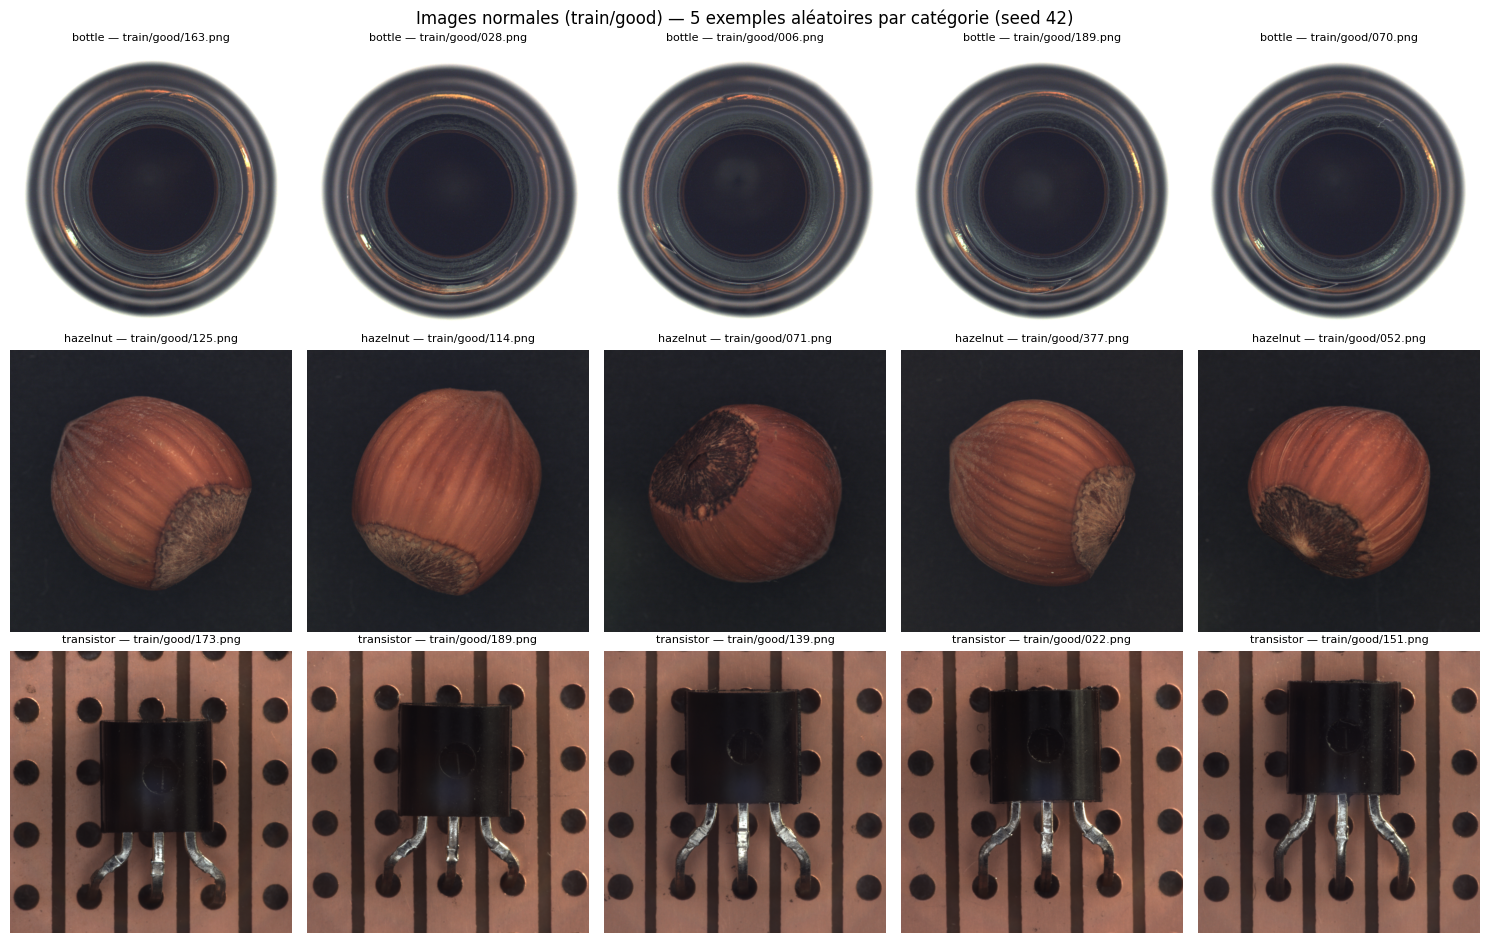

Figure enregistrée : /kaggle/working/eda_figures/01_normal_examples.png


In [2]:
N_NORMAL = 5                       # images normales affichées par catégorie
rng = random.Random(SEED)

fig, axes = plt.subplots(len(CATEGORIES), N_NORMAL, figsize=(3 * N_NORMAL, 3.2 * len(CATEGORIES)))
for row, cat in enumerate(CATEGORIES):
    paths = sorted((DATASET_ROOT / cat / "train" / "good").glob("*.png"))
    for col, p in enumerate(rng.sample(paths, N_NORMAL)):
        ax = axes[row, col]
        ax.imshow(load_rgb(p))
        ax.set_title(f"{cat} — train/good/{p.name}", fontsize=8)
        ax.axis("off")

fig.suptitle("Images normales (train/good) — 5 exemples aléatoires par catégorie (seed 42)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_normal_examples.png", dpi=110, bbox_inches="tight")
plt.show()
print("Figure enregistrée :", FIG_DIR / "01_normal_examples.png")

## Étape 4 — Défauts et masques
Pour chaque type de défaut : une image tirée au hasard (seed 43), son masque et la superposition
du masque en rouge, avec la part de l'image occupée par le défaut.

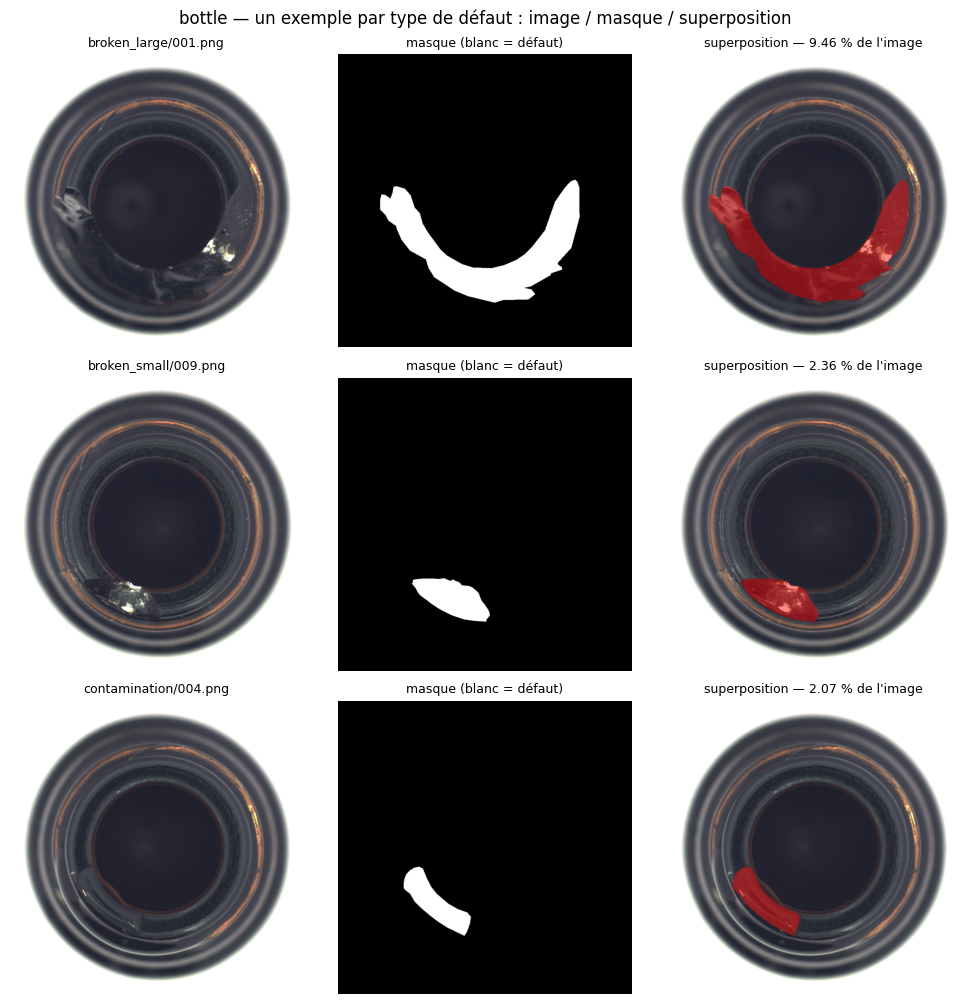

Figure enregistrée : /kaggle/working/eda_figures/02_defects_bottle.png


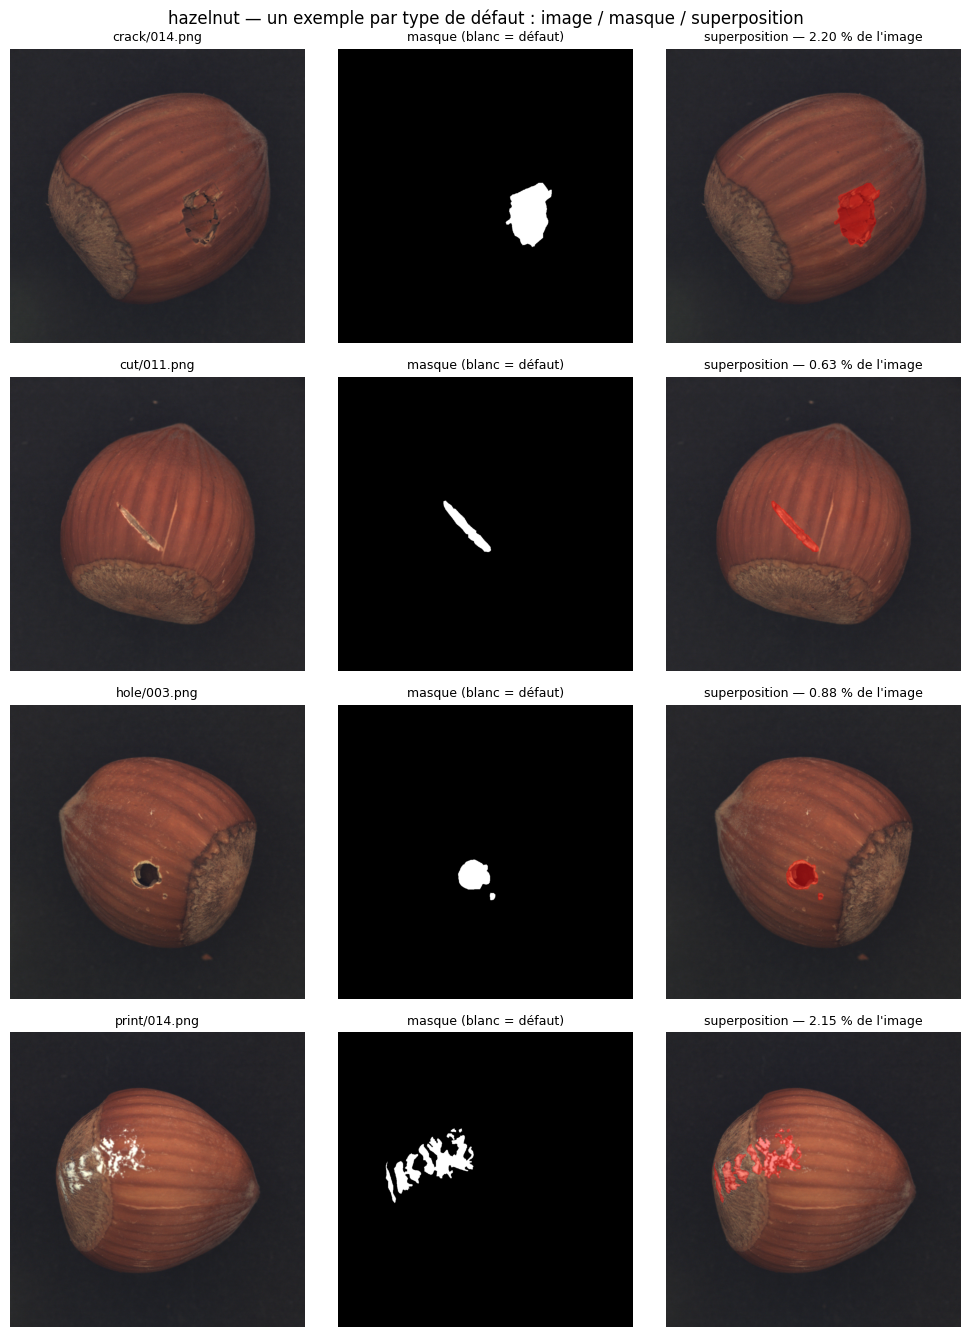

Figure enregistrée : /kaggle/working/eda_figures/02_defects_hazelnut.png


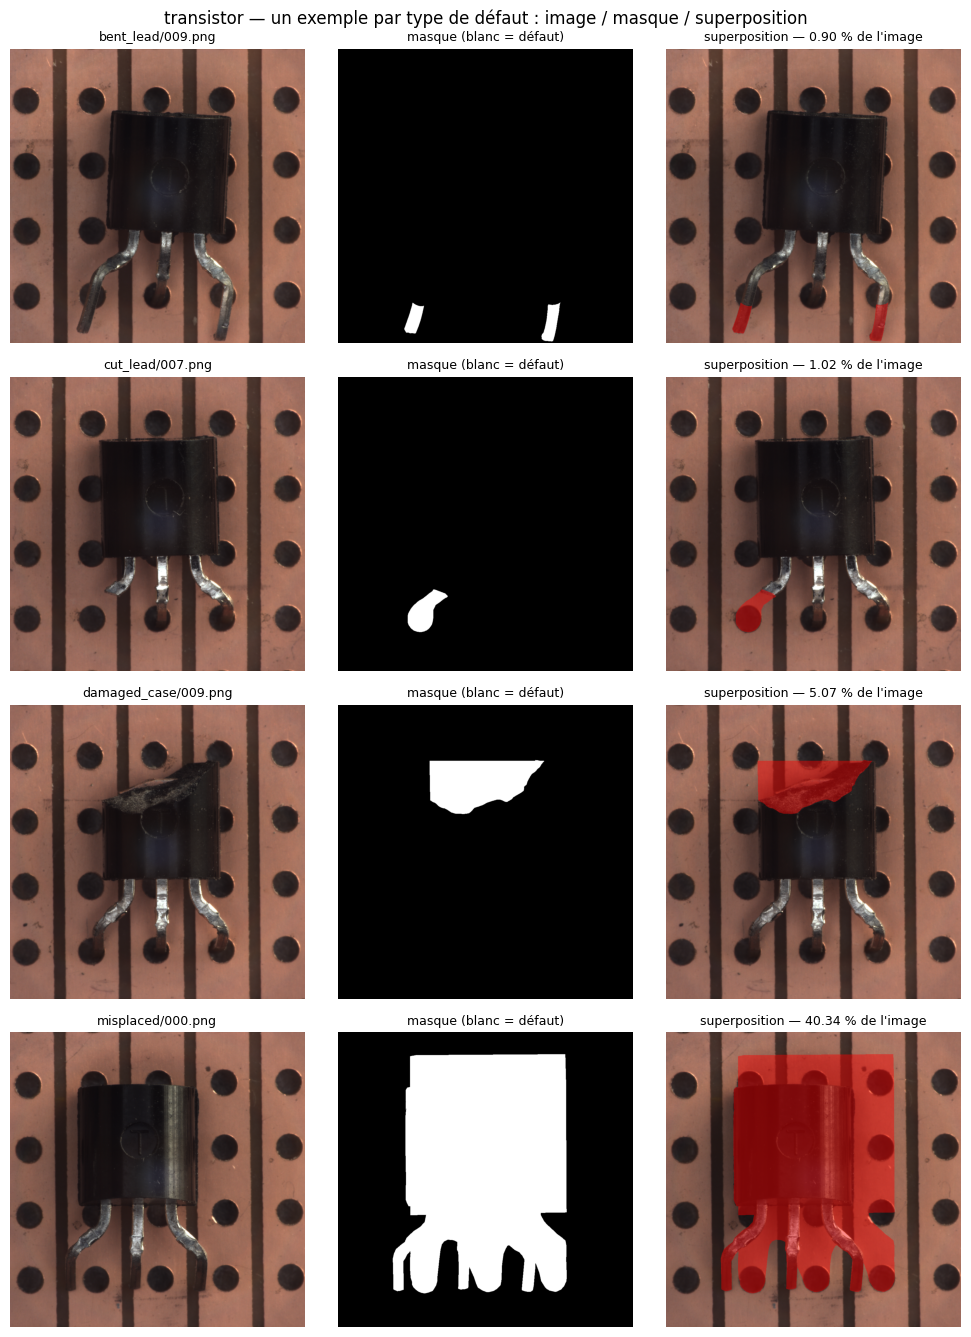

Figure enregistrée : /kaggle/working/eda_figures/02_defects_transistor.png


In [3]:
rng_def = random.Random(SEED + 1)  # générateur dédié aux défauts (indépendant de l'étape 3)

for cat in CATEGORIES:
    defects = DEFECT_TYPES[cat]
    fig, axes = plt.subplots(len(defects), 3, figsize=(10, 3.4 * len(defects)), squeeze=False)
    for row, d in enumerate(defects):
        paths = sorted((DATASET_ROOT / cat / "test" / d).glob("*.png"))
        p = rng_def.choice(paths)
        img, mask = load_rgb(p), load_mask(p)
        area_pct = 100 * mask.mean()
        panels = [(img, f"{d}/{p.name}"),
                  (mask, "masque (blanc = défaut)"),
                  (overlay(img, mask), f"superposition — {area_pct:.2f} % de l'image")]
        for col, (data, title) in enumerate(panels):
            ax = axes[row, col]
            ax.imshow(data, cmap="gray" if data.ndim == 2 else None)
            ax.set_title(title, fontsize=9)
            ax.axis("off")
    fig.suptitle(f"{cat} — un exemple par type de défaut : image / masque / superposition",
                 fontsize=12)
    fig.tight_layout()
    out = FIG_DIR / f"02_defects_{cat}.png"
    fig.savefig(out, dpi=100, bbox_inches="tight")
    plt.show()
    print("Figure enregistrée :", out)